# TravelEase

## Inference Engine

Creates the inference engine and visualizes input and output.

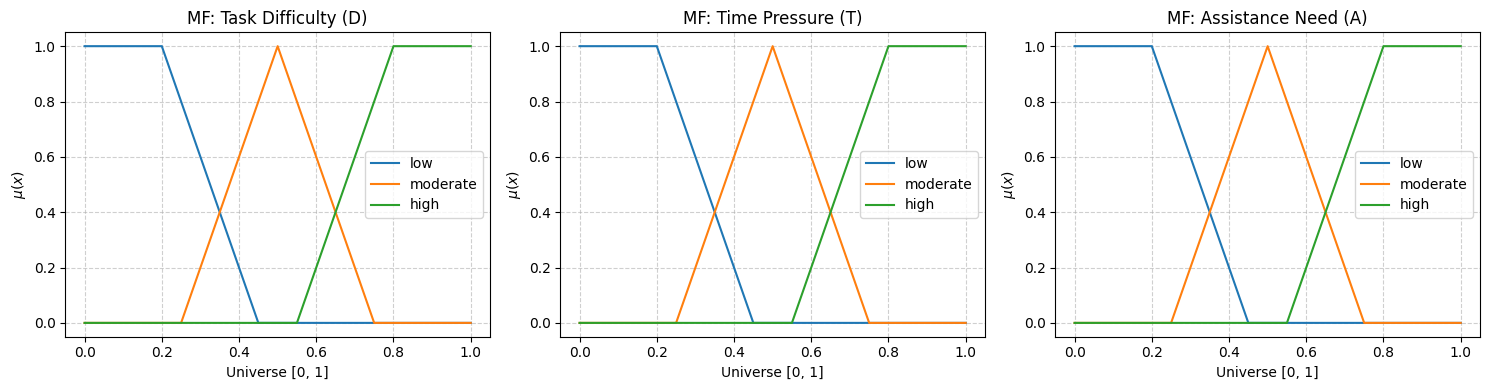

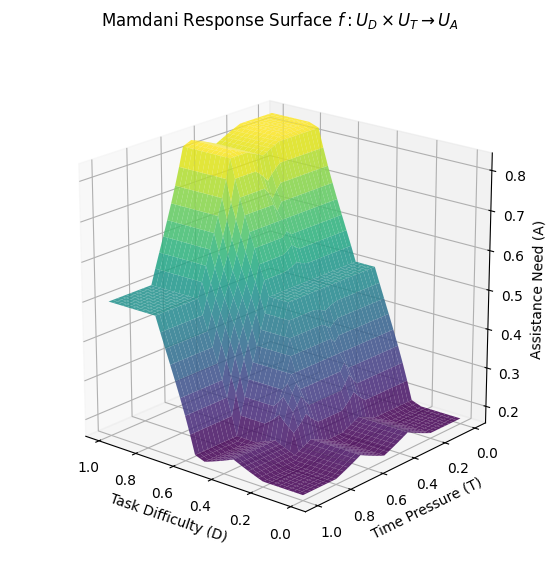

In [12]:
import json
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D
import numpy as np
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# ---------------------------------------------------------------------------
# 1. Universes of Discourse (fine-grained sampling)
# ---------------------------------------------------------------------------
u_fine = np.linspace(0.0, 1.0, 201)

difficulty = ctrl.Antecedent(u_fine, "difficulty")
time_pressure = ctrl.Antecedent(u_fine, "time_pressure")
assistance = ctrl.Consequent(u_fine, "assistance")

# ---------------------------------------------------------------------------
# 2. Membership Functions
# ---------------------------------------------------------------------------
# input 1: task difficulty D
difficulty["low"] = fuzz.trapmf(difficulty.universe, [0.0, 0.0, 0.20, 0.45])
difficulty["moderate"] = fuzz.trimf(difficulty.universe, [0.25, 0.50, 0.75])
difficulty["high"] = fuzz.trapmf(difficulty.universe, [0.55, 0.80, 1.00, 1.00])

# input 2: situational time pressure T
time_pressure["low"] = fuzz.trapmf(time_pressure.universe, [0.0, 0.0, 0.20, 0.45])
time_pressure["moderate"] = fuzz.trimf(time_pressure.universe, [0.25, 0.50, 0.75])
time_pressure["high"] = fuzz.trapmf(time_pressure.universe, [0.55, 0.80, 1.00, 1.00])

# output: assistance need A
assistance.defuzzify_method = "centroid"
assistance["low"] = fuzz.trapmf(assistance.universe, [0.0, 0.0, 0.20, 0.45])
assistance["moderate"] = fuzz.trimf(assistance.universe, [0.25, 0.50, 0.75])
assistance["high"] = fuzz.trapmf(assistance.universe, [0.55, 0.80, 1.00, 1.00])

# ---------------------------------------------------------------------------
# 3. Rule Base (3x3 rule matrix)
# ---------------------------------------------------------------------------
rules = [
    # low difficulty
    ctrl.Rule(difficulty["low"] & time_pressure["low"], assistance["low"]),
    ctrl.Rule(difficulty["low"] & time_pressure["moderate"], assistance["low"]),
    ctrl.Rule(difficulty["low"] & time_pressure["high"], assistance["low"]),
    
    # moderate difficulty
    ctrl.Rule(difficulty["moderate"] & time_pressure["low"], assistance["moderate"]),
    ctrl.Rule(difficulty["moderate"] & time_pressure["moderate"],assistance["moderate"]),
    ctrl.Rule(difficulty["moderate"] & time_pressure["high"], assistance["low"]),
    
    # high difficulty
    ctrl.Rule(difficulty["high"] & time_pressure["low"], assistance["high"]),
    ctrl.Rule(difficulty["high"] & time_pressure["moderate"], assistance["high"]),
    ctrl.Rule(difficulty["high"] & time_pressure["high"], assistance["moderate"]),
]

system = ctrl.ControlSystem(rules)
simulator = ctrl.ControlSystemSimulation(system)

# ---------------------------------------------------------------------------
# 4. Quality Assurance (membership functions and response surface plots
# ---------------------------------------------------------------------------
def plot_qa_diagnostics():
    
  # plot membership functions
  fig, axes = plt.subplots(1, 3, figsize=(15, 4))
  for ax, var, title in zip(
      axes,
      [difficulty, time_pressure, assistance],
      ["Task Difficulty (D)", "Time Pressure (T)", "Assistance Need (A)"],
  ):
    for label, term in var.terms.items():
      ax.plot(var.universe, term.mf, label=label)
    ax.set_title(f"MF: {title}")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xlabel("Universe [0, 1]")
    ax.set_ylabel(r"$\mu(x)$")
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend()
  plt.tight_layout()
  plt.show()

  # compute 3D response surface
  n_eval = 41
  d_eval = np.linspace(0.0, 1.0, n_eval)
  t_eval = np.linspace(0.0, 1.0, n_eval)
  d_mesh, t_mesh = np.meshgrid(d_eval, t_eval)
  surf = np.zeros_like(d_mesh)

  for i in range(n_eval):
    for j in range(n_eval):
      simulator.input["difficulty"] = d_mesh[i, j]
      simulator.input["time_pressure"] = t_mesh[i, j]
      simulator.compute()
      surf[i, j] = simulator.output["assistance"]

  # plot 3D response surface
  fig = plt.figure(figsize=(10, 7))
  ax = fig.add_subplot(111, projection="3d")
  ax.plot_surface(
      d_mesh, t_mesh, surf, cmap="viridis", edgecolor="none", alpha=0.85
  )
  ax.set_xlabel("Task Difficulty (D)")
  ax.set_ylabel("Time Pressure (T)")
  ax.set_zlabel("Assistance Need (A)")
  ax.set_title("Mamdani Response Surface $f: U_D \\times U_T \\to U_A$")

  # set view trajectory
  ax.view_init(elev=20, azim=130)
    
  # zoom out, so z-axis is visible
  ax.set_box_aspect((1, 1, 1), zoom=0.9)

  plt.show()

if __name__ == "__main__":
  plot_qa_diagnostics()

## Lookup Table Export

Evaluates the 11x11 grid points and exports the LUT as a Kotlin code snippet.

In [14]:
GRID_POINTS = 11  # discrete inputs: 0.0, 0.1, ..., 1.0 (step = 0.1)
d_samples = np.linspace(0.0, 1.0, GRID_POINTS)
t_samples = np.linspace(0.0, 1.0, GRID_POINTS)

lut = np.zeros((GRID_POINTS, GRID_POINTS), dtype=np.float32)

for i, d in enumerate(d_samples):
  for j, t in enumerate(t_samples):
    simulator.input["difficulty"] = d
    simulator.input["time_pressure"] = t
    simulator.compute()
    lut[i, j] = simulator.output["assistance"]

print("// generated 11x11 Flat FloatArray (Row-Major: D x T)")
print(f"// reachable Centroid Range: min={lut.min():.4f}, max={lut.max():.4f}\n")
print("private val LUT_DATA = floatArrayOf(")
for row_idx, row in enumerate(lut):
  row_str = ", ".join(f"{val:.4f}f" for val in row)
  print(f"    {row_str}, // D = {row_idx * 0.1:.1f}")
print(")")

// generated 11x11 Flat FloatArray (Row-Major: D x T)
// reachable Centroid Range: min=0.1705, max=0.8295

private val LUT_DATA = floatArrayOf(
    0.1705f, 0.1705f, 0.1705f, 0.1900f, 0.1900f, 0.1705f, 0.1900f, 0.1900f, 0.1705f, 0.1705f, 0.1705f, // D = 0.0
    0.1705f, 0.1705f, 0.1705f, 0.1900f, 0.1900f, 0.1705f, 0.1900f, 0.1900f, 0.1705f, 0.1705f, 0.1705f, // D = 0.1
    0.1705f, 0.1705f, 0.1705f, 0.1900f, 0.1900f, 0.1705f, 0.1900f, 0.1900f, 0.1705f, 0.1705f, 0.1705f, // D = 0.2
    0.2711f, 0.2711f, 0.2711f, 0.2711f, 0.2711f, 0.2711f, 0.2711f, 0.2711f, 0.1900f, 0.1900f, 0.1900f, // D = 0.3
    0.4248f, 0.4248f, 0.4248f, 0.4248f, 0.4248f, 0.4248f, 0.4248f, 0.2711f, 0.1900f, 0.1900f, 0.1900f, // D = 0.4
    0.5000f, 0.5000f, 0.5000f, 0.5000f, 0.5000f, 0.5000f, 0.4248f, 0.2711f, 0.1705f, 0.1705f, 0.1705f, // D = 0.5
    0.5752f, 0.5752f, 0.5752f, 0.5752f, 0.5752f, 0.5752f, 0.5000f, 0.3667f, 0.2711f, 0.2711f, 0.2711f, // D = 0.6
    0.7289f, 0.7289f, 0.7289f, 0.7289f, 0.7289f, 0.7289f, 